# Watchlist

A price projection from the options market and a buy/sell score from analyst ratings, for each stock on the list.

## Setup

Imports, the Finnhub key from `.env`, the tickers to follow and the option score weights.

In [5]:
import seaborn as sns
from dotenv import load_dotenv
from matplotlib.pyplot import subplots, tight_layout
from matplotlib.ticker import AutoMinorLocator
from pandas import concat
from foundation.entities.options import OptionsEnum
from stk_guide.ml.scoring.scorer import RatingsScorer
from watchlist import Charts, Watchlist

In [6]:
load_dotenv("../../.env")
sns.set_style("whitegrid")

SYMBOLS = [
    "AAPL", "NVDA", "META", "INTC", "AMZN", "GOOGL", "MSFT", "AVGO", "RDDT", "V", "UBER", "HIMS",
    "LLY", "NVO", "VRTX", "ABBV", "ISRG", "HCA", "UNH", "MA", "PYPL", "AXP", "BLK", "SNOW",
]
WEIGHTS = {OptionsEnum.VOLUME: 10, OptionsEnum.PERCENTCHANGE: 20}
EXPIRATION, PROJECTED = OptionsEnum.EXPIRATION.value, OptionsEnum.PROJECTED_PRICE_v1.value

## Download

I download company info, the next option expirations and the Robinhood and Finnhub analyst ratings for every ticker once, then summarize the calls per expiration.

In [2]:
watchlist = Watchlist(SYMBOLS)
watchlist.load()
calls = watchlist.calls(WEIGHTS)

## Price projection

Expected change from today's price at each expiration, from the top-scored call (strike plus ask, scored by volume and price change).

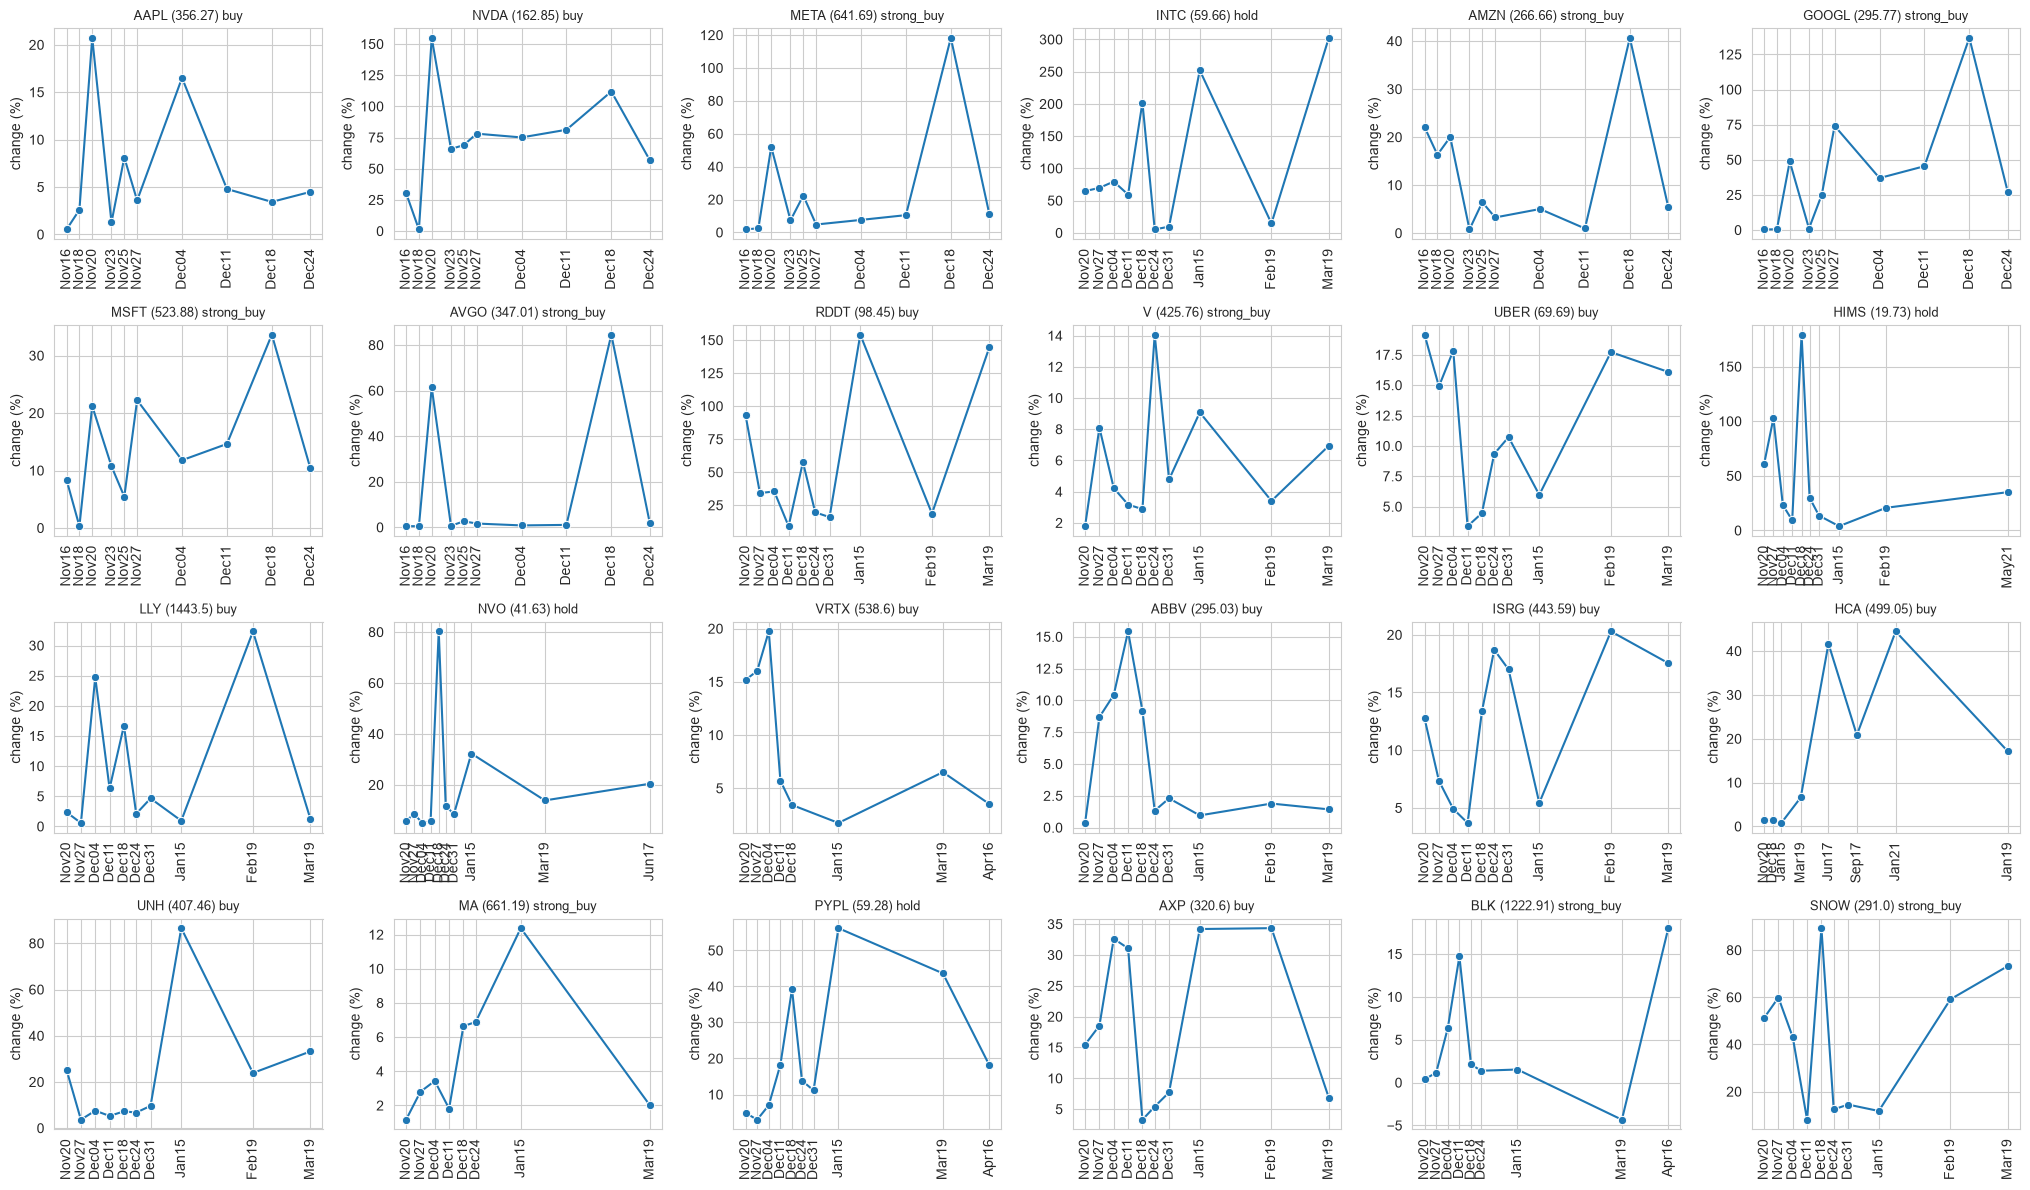

In [3]:
for ax, stock in Charts.panels(watchlist.stocks):
    summary = calls[stock.symbol]
    change = (summary[PROJECTED] / stock.info["currentPrice"] - 1) * 100
    sns.lineplot(x=summary[EXPIRATION], y=change, marker="o", ax=ax)
    ax.set_xticks(summary[EXPIRATION], [day.strftime("%b%d") for day in summary[EXPIRATION]], rotation=90)
    ax.set(xlabel="", ylabel="change (%)")
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
tight_layout()

## Recommendations

The latest analyst rating per source scored from 0 (sell) to 1 (buy); tick labels add Yahoo's recommendation.

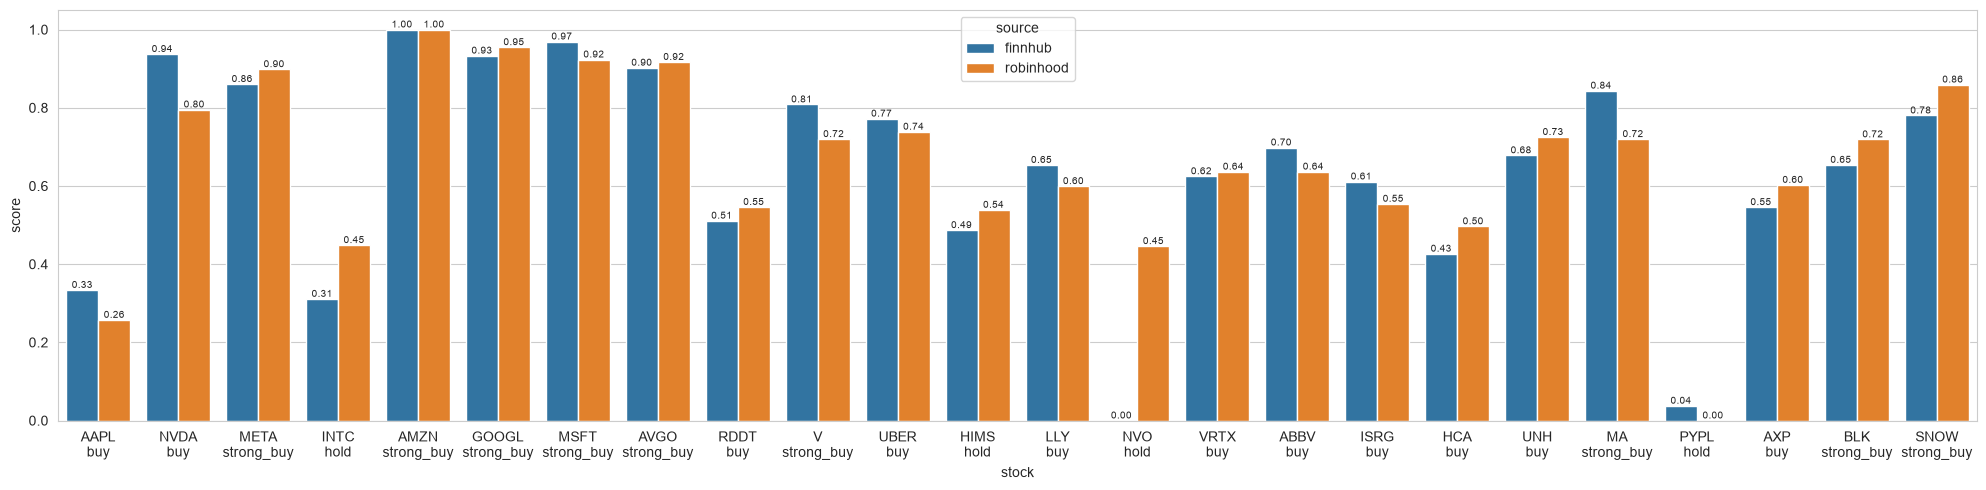

In [4]:
ratings = watchlist.ratings()
latest = ratings.sort_values("date").groupby(["stock", "source"]).tail(1)
scores = concat(
    group.assign(score=1 - RatingsScorer()(group).to_numpy()) for _, group in latest.groupby("source")
)
_, ax = subplots(figsize=(20, 5))
sns.barplot(scores, x="stock", y="score", hue="source", order=SYMBOLS, ax=ax)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", fontsize=7)
ax.set_xticks(range(len(SYMBOLS)), [f"{stock.symbol}\n{stock.info.get('recommendationKey')}" for stock in watchlist.stocks])
tight_layout()